![Banner](../images/09_04_banner_rs_uav.png)


# Season-Long Phenotyping 

The earlier notebooks each measure one trait. A season of phenotyping needs those traits together, one row per date.


## Overview

The table holds canopy cover, greenness, yellowing, plant and panicle counts and height, followed through the season and summarised as growth curves and stage dates. This notebook builds that table from the LUMS rice frames with `rs.uav.trait_table` and `rs.uav.frame_traits`, fits logistic curves with `rs.uav.fit_logistic`, finds stage dates with `rs.uav.detect_stages`, adds a short thermal water-stress section with `rs.uav.cwsi`, and closes with one reproducible function that goes from a folder of frames to CSV and GeoPackage outputs and a short report.


## Core concepts

### Learning objectives

1. Compute several traits per frame in one pass and aggregate them per flight date.
2. Combine per-date traits from different methods and notebooks into one tidy table.
3. Fit logistic growth (and decline) curves and derive onset, mid-point and plateau dates.
4. Compute the Crop Water Stress Index from thermal imagery three ways.
5. Package the workflow as a reproducible pipeline with CSV, GeoPackage and report outputs.

### Data

| Data | Type |
|---|---|
| LUMS rice frames, 11 dates from 22 Aug to 3 Oct 2025 | **Real** (CC BY 4.0) |
| Plot heights from notebook 09_04_06 and panicle candidates from 09_04_09 | **Saved results**, merged when those files are present |
| Thermal frame in Section 6, built from a real RGB frame | **Simulated** |

### Contents

1. Setup
2. Traits for every frame
3. One table from many methods
4. Growth curves and stage dates
5. Height growth (synthetic DEMs)
6. Thermal imagery and the Crop Water Stress Index
7. Capstone: one reproducible pipeline
8. Summary and exercises


## Setup

**Installation.** This notebook needs installation option 5 (core, spatial analysis, spatial statistics, geostatistics and remote sensing): `pip install "geolattice[remote-sensing]"`. See "Installation options" in the GeoLattice README.

In [1]:
import warnings  # control warning messages
warnings.filterwarnings("ignore")  # hide library warnings

from pathlib import Path  # file paths

import numpy as np  # arrays
import pandas as pd  # tables
import xarray as xr  # labelled arrays
import geopandas as gpd  # GeoPackage export
import matplotlib.pyplot as plt  # figures
from shapely.geometry import box  # zone polygons

import geolattice.rsense as rs  # GeoLattice remote sensing (rs.uav = drone tools)

plt.rcParams.update({"figure.dpi": 110})  # figure resolution
DATA = Path("../../../../Data/08_remote_sensing/08_04_uav")
LUMS = DATA / "infrastructure-free-uav-phenotyping"
OUT = Path("outputs"); OUT.mkdir(exist_ok=True)
GSD = 0.00185  # m/px of the 6 m frames
HUE_MAX = 62.0  # green/yellow hue cut calibrated in notebook 09_04_08
EXG_COVER = 0.10  # fixed ExG threshold for cover (Otsu fails after canopy closure, 09_04_04)

## Traits for every frame

`rs.uav.frame_traits(image, ...)` returns a dictionary of standard RGB traits for one frame:
canopy cover, mean ExG, VARI and TGI inside the vegetation mask, the senescent fraction
(colour rule with the calibrated hue) and, optionally, a plant count. `rs.uav.trait_table`
runs it over every catalogue row. Frames are read at `max_dim=1280` and with their GSD, so
coordinates (and the plant spacing) are in metres.


In [2]:
cat = rs.uav.build_catalog(LUMS.parent)
cat = cat[cat.dataset.str.startswith("infra")].assign(crop="rice").reset_index(drop=True)

def traits(image):
    t = rs.uav.frame_traits(image, threshold=EXG_COVER, hue_max=HUE_MAX, count=True,
                            min_distance=0.15, sigma=0.03)  # metres
    area = image.sizes["x"] * image.sizes["y"] * image.attrs["gsd_m"] ** 2
    t["plants_per_m2"] = t.pop("plant_count") / area
    return t

table = rs.uav.trait_table(cat, traits, max_dim=1280, gsd=GSD)
table.drop(columns=["path"]).head()

,dataset,crop,session,date,band,rig,frame,canopy_cover,ExG_veg_mean,VARI_veg_mean,TGI_veg_mean,senescent_frac,plants_per_m2
0,infrastructure-free-uav-phenotyping,rice,2025-08-22,2025-08-22,RGB,,frame1123,0.589039,0.271850,0.103250,14.685521,0.174550,1.761333
1,infrastructure-free-uav-phenotyping,rice,2025-08-22,2025-08-22,RGB,,frame1278,0.462210,0.248196,0.061859,13.831245,0.315048,2.395413
2,infrastructure-free-uav-phenotyping,rice,2025-08-22,2025-08-22,RGB,,frame130,0.836247,0.293312,0.114063,15.832253,0.179318,2.994267
3,infrastructure-free-uav-phenotyping,rice,2025-08-22,2025-08-22,RGB,,frame1428,0.920698,0.327130,0.190375,16.968748,0.040292,6.023760
4,infrastructure-free-uav-phenotyping,rice,2025-08-22,2025-08-22,RGB,,frame1464,0.872150,0.286732,0.185928,14.766328,0.041499,5.389680


In [3]:
per_date = rs.uav.summarize_dates(table, ["canopy_cover", "ExG_veg_mean", "VARI_veg_mean", "TGI_veg_mean",
                                          "senescent_frac", "plants_per_m2"])
cols = [c for c in per_date.columns if c.endswith("_mean")]
per_date[["date"] + cols].round(3)

,date,canopy_cover_mean,ExG_veg_mean_mean,VARI_veg_mean_mean,TGI_veg_mean_mean,senescent_frac_mean,plants_per_m2_mean
0,2025-08-22,0.732,0.292,0.155,15.403,0.129,3.720
1,2025-08-28,0.648,0.255,0.104,13.927,0.239,2.575
2,2025-09-04,0.655,0.302,0.225,15.557,0.111,3.628
3,2025-09-05,0.717,0.288,0.127,15.551,0.167,2.998
4,2025-09-09,0.765,0.297,0.176,15.429,0.038,4.361
5,2025-09-12,0.849,0.319,0.212,16.520,0.049,5.059
6,2025-09-17,0.818,0.297,0.145,15.816,0.093,4.537
7,2025-09-19,0.852,0.308,0.112,16.913,0.065,4.372
8,2025-09-26,0.868,0.272,0.086,15.175,0.090,5.076
9,2025-10-01,0.861,0.255,0.062,14.468,0.232,5.548


## One table from many methods

Other notebooks saved their own per-frame or per-plot results. They are merged by date when
the files exist (run 09_04_06 and 09_04_09 first to include them). Each source is flagged so
that nobody mistakes a synthetic or stand-in trait for a measurement.


In [4]:
season = per_date[["date"] + cols].rename(columns=lambda c: c.replace("_mean", ""))
season["source_rgb"] = "LUMS frames"

f_pan = OUT / "panicle_candidates_frames.csv"
if f_pan.exists():
    pan = pd.read_csv(f_pan, parse_dates=["date"]).groupby("date").per_m2.mean().rename("panicle_candidates_per_m2")
    season = season.merge(pan, on="date", how="left")
f_h = OUT / "plot_heights_validation.csv"
if f_h.exists():
    h = pd.read_csv(f_h, parse_dates=["date"]).groupby("date")["per-date trend"].mean().rename("height_m_synthetic")
    season = season.merge(h, on="date", how="outer")
season = season.sort_values("date").reset_index(drop=True)
season.round(3)

,date,canopy_cover,ExG_veg,VARI_veg,TGI_veg,senescent_frac,plants_per_m2,source_rgb,panicle_candidates_per_m2,height_m_synthetic
0,2025-08-22,0.732,0.292,0.155,15.403,0.129,3.720,LUMS frames,NaN,NaN
1,2025-08-28,0.648,0.255,0.104,13.927,0.239,2.575,LUMS frames,NaN,NaN
2,2025-09-04,0.655,0.302,0.225,15.557,0.111,3.628,LUMS frames,NaN,0.528
3,2025-09-05,0.717,0.288,0.127,15.551,0.167,2.998,LUMS frames,NaN,NaN
4,2025-09-09,0.765,0.297,0.176,15.429,0.038,4.361,LUMS frames,NaN,NaN
5,2025-09-12,0.849,0.319,0.212,16.520,0.049,5.059,LUMS frames,NaN,0.688
6,2025-09-17,0.818,0.297,0.145,15.816,0.093,4.537,LUMS frames,1.515,NaN
7,2025-09-19,0.852,0.308,0.112,16.913,0.065,4.372,LUMS frames,5.439,0.847
8,2025-09-26,0.868,0.272,0.086,15.175,0.090,5.076,LUMS frames,3.678,1.008
9,2025-10-01,0.861,0.255,0.062,14.468,0.232,5.548,LUMS frames,3.787,NaN


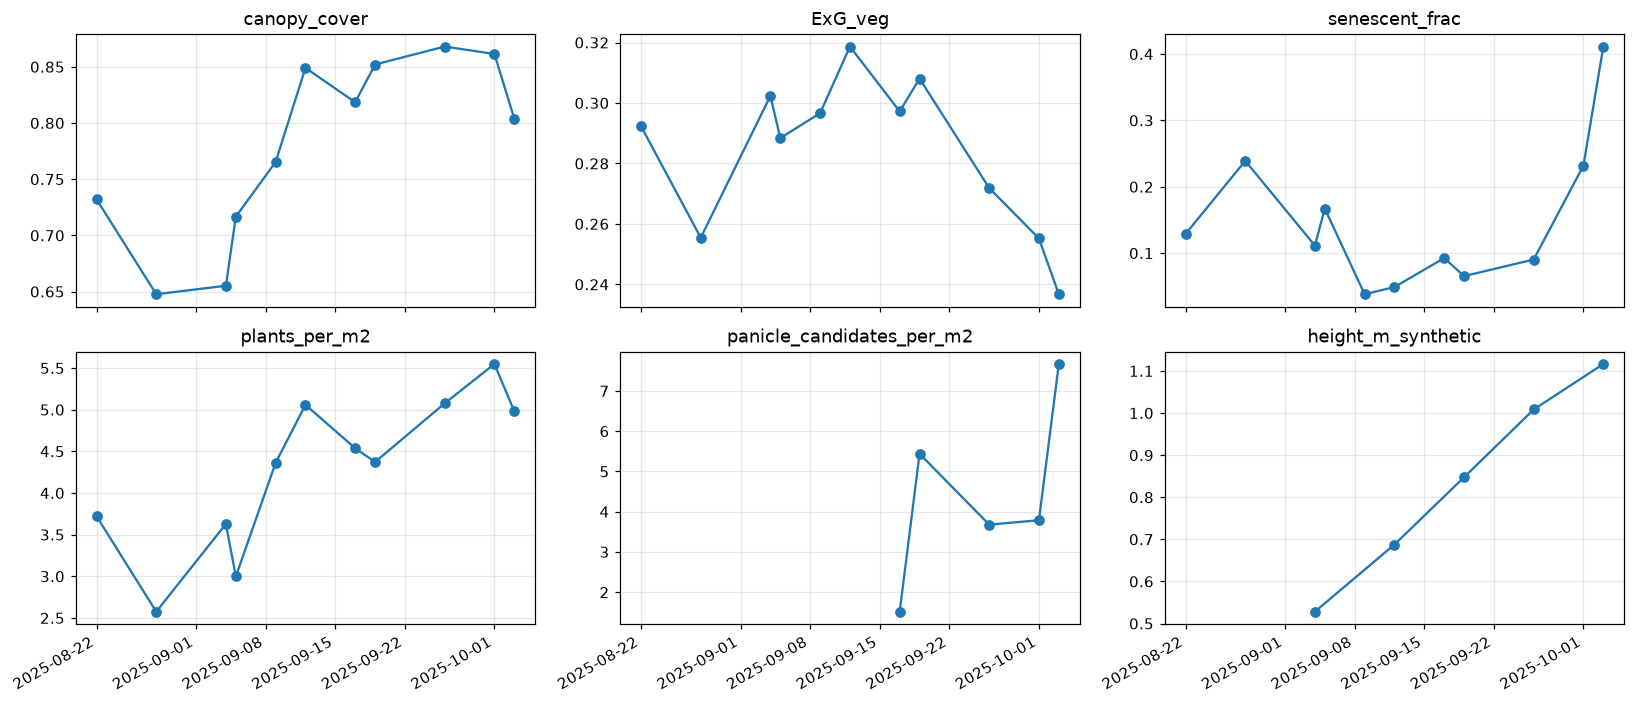

In [5]:
plot_cols = [c for c in ["canopy_cover", "ExG_veg", "senescent_frac", "plants_per_m2",
                         "panicle_candidates_per_m2", "height_m_synthetic"] if c in season]
fig, axes = plt.subplots(2, 3, figsize=(15, 6.5), sharex=True)
for ax, c in zip(axes.flat, plot_cols):
    d = season[["date", c]].dropna()
    ax.plot(d.date, d[c], "o-"); ax.set_title(c); ax.grid(alpha=0.3)
for ax in axes.flat[len(plot_cols):]:
    ax.axis("off")
fig.autofmt_xdate(); plt.tight_layout(); plt.show()

## Growth curves and stage dates

A four-parameter logistic, $y = \text{base} + \text{amp} / (1 + e^{-r(t - t_{mid})})$, fits
most growth traits. `rs.uav.fit_logistic(dates, values)` returns the parameters, the
inflection date and the maximum growth rate; `rs.uav.detect_stages(fit)` turns the fit into
the dates at which 10 %, 50 % and 90 % of the change is reached (onset, mid, plateau).
Fitting to all frames, not only the date means, keeps the frame-to-frame spread in the fit.

With flights a week apart and noisy frames, an unconstrained fit can collapse into a step
between two flights, with "stages" hours apart. `fit_logistic` therefore bounds the rate so
the 10-90 % transition lasts at least `min_transition_days` (default: twice the median gap
between flights); a transition shorter than that cannot be resolved by the data anyway.


In [6]:
fit_cov = rs.uav.fit_logistic(table.date, table.canopy_cover)
print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in fit_cov.items() if k not in ("predict", "origin")})
stages_cov = rs.uav.detect_stages(fit_cov)
stages_cov

{'base': 0.678, 'amp': 0.1674, 'rate': 0.4878, 't_mid': 17.5112, 'mid_date': Timestamp('2025-09-08 12:16:08.842646967'), 'max_rate': 0.0204, 'r2': 0.31}


,stage,fraction,day,date,value
0,onset,0.1,13.006653,2025-09-04 00:09:34.803618118,0.694763
1,mid,0.5,17.511213,2025-09-08 12:16:08.842646967,0.761706
2,plateau,0.9,22.015774,2025-09-13 00:22:42.881675815,0.828649


Yellowing is the mirror image: the green fraction of plant pixels declines towards maturity.
`decreasing=True` starts the fit accordingly, and `limits=(0, 1)` keeps both ends of the curve
inside the range a fraction can take. Without it, a decline that has only begun by the last
flight is extrapolated to impossible negative values. Even so, only the start of yellowing is
supported by the data; later stages lie beyond 3 October.


In [7]:
green = 1 - table.senescent_frac
fit_green = rs.uav.fit_logistic(table.date, green, decreasing=True, limits=(0, 1))
stages_green = rs.uav.detect_stages(fit_green, levels={"start of yellowing": 0.1})
print(f"green fraction fit: from {fit_green['base']:.2f} towards {fit_green['base'] + fit_green['amp']:.2f}, "
      f"R2 = {fit_green['r2']:.3f}")
stages_green

green fraction fit: from 0.89 towards 0.00, R2 = 0.419


,stage,fraction,day,date,value
0,start of yellowing,0.1,38.959074,2025-09-29 23:01:04.006710646,0.803766


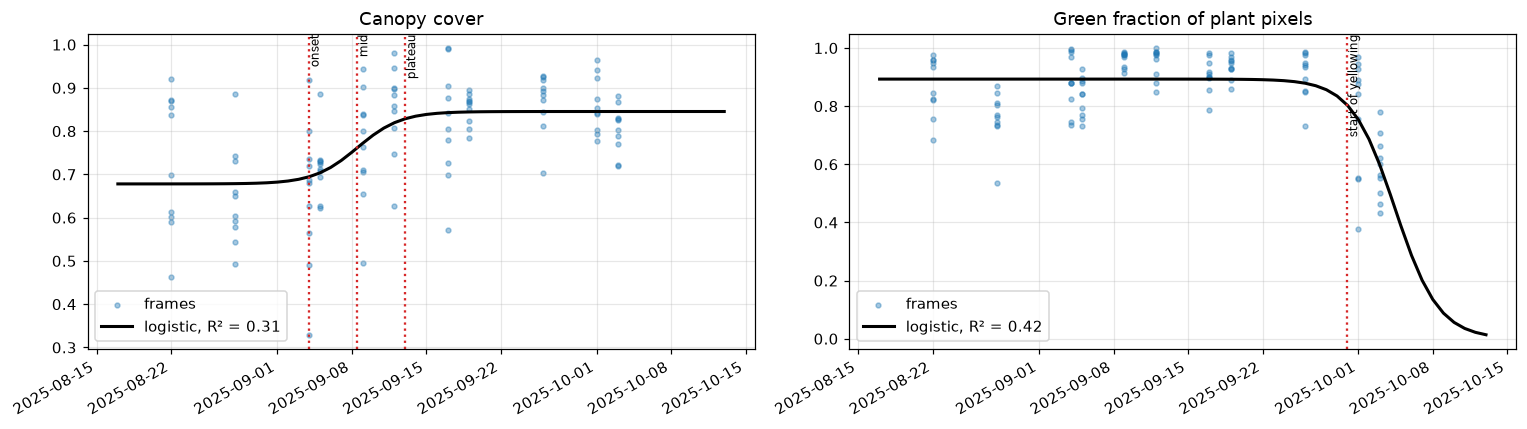

In [8]:
t_fine = pd.date_range(table.date.min() - pd.Timedelta(days=5), table.date.max() + pd.Timedelta(days=10))
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, fit, y, title, st in [(axes[0], fit_cov, table.canopy_cover, "Canopy cover", stages_cov),
                              (axes[1], fit_green, green, "Green fraction of plant pixels", stages_green)]:
    ax.scatter(table.date, y, s=10, alpha=0.4, label="frames")
    ax.plot(t_fine, fit["predict"](t_fine), "k-", lw=2, label=f"logistic, R² = {fit['r2']:.2f}")
    for _, s in st.iterrows():
        ax.axvline(s.date, ls=":", color="C3"); ax.text(s.date, ax.get_ylim()[1], s.stage, rotation=90, va="top", fontsize=8)
    ax.set_title(title); ax.legend(loc="lower left"); ax.grid(alpha=0.3)
fig.autofmt_xdate(); plt.tight_layout(); plt.show()

In [9]:
rates = rs.uav.growth_rates(per_date.rename(columns={"canopy_cover_mean": "cover"}), "cover")
rates[["date", "cover", "cover_per_day"]].round(4)

,date,cover,cover_per_day
0,2025-08-22,0.7320,NaN
1,2025-08-28,0.6476,-0.0141
2,2025-09-04,0.6552,0.0011
3,2025-09-05,0.7166,0.0614
4,2025-09-09,0.7653,0.0122
5,2025-09-12,0.8490,0.0279
6,2025-09-17,0.8184,-0.0061
7,2025-09-19,0.8520,0.0168
8,2025-09-26,0.8680,0.0023
9,2025-10-01,0.8614,-0.0013


Read the curves with their caveats: each date's ten frames come from different places, the
fixed ExG threshold also counts weedy soil early on (09_04_04), and the colour rule calls dry
soil "senescent" before the canopy closes (09_04_08). The fitted shapes are plausible; the
exact dates carry several days of uncertainty.


## Height growth (synthetic DEMs)

Height comes from the DEM workflow of notebook 09_04_06, on synthetic DEMs, so it is shown
only to complete the trait set. With real LUMS DEMs the same code applies.


In [10]:
if "height_m_synthetic" in season:
    hd = season[["date", "height_m_synthetic"]].dropna()
    fit_h = rs.uav.fit_logistic(hd.date, hd.height_m_synthetic) if len(hd) >= 4 else None
    if fit_h is not None:
        print(f"height: max rate {fit_h['max_rate'] * 100:.2f} cm/day around {fit_h['mid_date']:%d %b}, R2 {fit_h['r2']:.3f}")
        display(rs.uav.detect_stages(fit_h))
        print("Five dates on a near-linear rise: onset and plateau are extrapolated beyond the flights.")
else:
    print("Run notebook 09_04_06 first to add synthetic plot heights.")

height: max rate 2.41 cm/day around 16 Sep, R2 1.000


,stage,fraction,day,date,value
0,onset,0.1,-8.242900,2025-08-26 18:10:13.475199845,0.428829
1,mid,0.5,12.827518,2025-09-16 19:51:37.536138856,0.799210
2,plateau,0.9,33.897935,2025-10-07 21:33:01.597077867,1.169590


Five dates on a near-linear rise: onset and plateau are extrapolated beyond the flights.


## Thermal imagery and the Crop Water Stress Index

A transpiring canopy is cooler than the air; a water-stressed one closes its stomata and
warms up. The Crop Water Stress Index scales canopy temperature $T_c$ between a wet (fully
transpiring) and a dry (non-transpiring) limit:

$$CWSI = \frac{T_c - T_{wet}}{T_{dry} - T_{wet}}$$

`rs.uav.cwsi` offers three ways to set the limits: `statistical` (low and high percentiles of
canopy pixels), `reference` (measured wet and dry reference surfaces) and `empirical` (Idso's
non-water-stressed baseline $T_c - T_a = a + b \cdot VPD$, with $b < 0$).

No thermal camera flew over the LUMS field, so a **synthetic** thermal frame is built from a
real RGB frame: soil and water get soil temperature, the canopy gets the unstressed baseline
temperature plus a stress pattern (a dry patch on one side), and a radiometric camera's raw
counts are simulated so that `rs.uav.raw_to_celsius` can convert them back.


In [11]:
rgb_img = rs.uav.read_frame(sorted((LUMS / "2025-09-12").glob("*.png"))[3], max_dim=960)
veg = rs.uav.exg_plant_mask(rgb_img, min_area=200).astype(bool)
ta, vpd = 33.0, 2.6  # air temperature (°C) and vapour pressure deficit (kPa) at flight time
t_wet_true = ta + 3.38 - 3.25 * vpd  # Idso (1982) wheat-like baseline as stand-in for rice
t_dry_true = ta + 5.0
rows_, cols_ = veg.shape
xx = np.linspace(0, 1, cols_)[None, :].repeat(rows_, 0)
stress_true = np.clip((xx - 0.45) / 0.4, 0, 1) * 0.8  # dry patch towards the right
rng = np.random.default_rng(1)
tc = np.where(veg, t_wet_true + stress_true * (t_dry_true - t_wet_true), ta + 9.0) + rng.normal(0, 0.4, veg.shape)
raw = xr.DataArray(((tc + 273.15) / 0.04).round().astype("uint16"), dims=("y", "x"),
                   coords={"y": rgb_img.y, "x": rgb_img.x})  # radiometric counts
temp = rs.uav.raw_to_celsius(raw)  # back to °C (gain 0.04 K/count)
veg_da = xr.DataArray(veg, dims=("y", "x"), coords=temp.coords)
print(f"Ta {ta} °C, VPD {vpd} kPa: true Twet {t_wet_true:.1f} °C, Tdry {t_dry_true:.1f} °C")

methods = {
    "statistical (5-95 %)": rs.uav.cwsi(temp, method="statistical", vegetation=veg_da),
    "reference": rs.uav.cwsi(temp, method="reference", t_wet=t_wet_true, t_dry=t_dry_true, vegetation=veg_da),
    "empirical (Idso)": rs.uav.cwsi(temp, method="empirical", air_temp=ta, vpd=vpd, vegetation=veg_da),
}
truth_c = np.where(veg, stress_true, np.nan)
pd.DataFrame({k: {"Twet": v.attrs["t_wet"], "Tdry": v.attrs["t_dry"], "mean CWSI": float(v.mean()),
                  "RMSE vs truth": float(np.sqrt(np.nanmean((v.values - truth_c) ** 2)))} for k, v in methods.items()}).T.round(3)

Ta 33.0 °C, VPD 2.6 kPa: true Twet 27.9 °C, Tdry 38.0 °C


,Twet,Tdry,mean CWSI,RMSE vs truth
statistical (5-95 %),27.41,36.25,0.386,0.115
reference,27.93,38.00,0.295,0.034
empirical (Idso),27.93,38.00,0.295,0.034


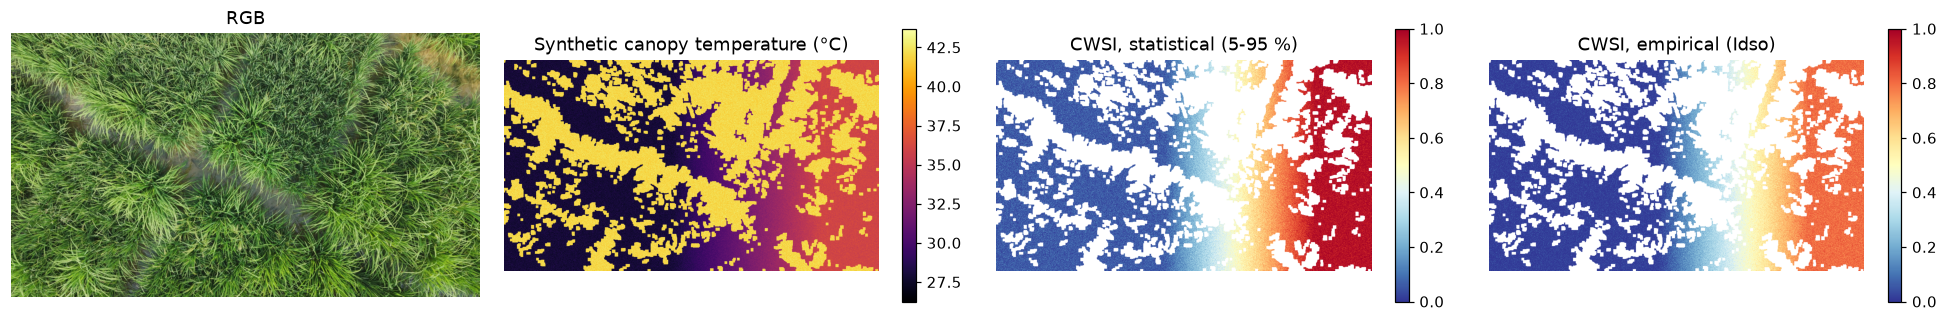

In [12]:
fig, axes = plt.subplots(1, 4, figsize=(18, 3.4))
axes[0].imshow(rs.uav.to_rgb_array(rgb_img)); axes[0].set_title("RGB")
im = axes[1].imshow(temp, cmap="inferno"); axes[1].set_title("Synthetic canopy temperature (°C)"); plt.colorbar(im, ax=axes[1], shrink=0.8)
for ax, k in zip(axes[2:], ["statistical (5-95 %)", "empirical (Idso)"]):
    im = ax.imshow(methods[k], cmap="RdYlBu_r", vmin=0, vmax=1); ax.set_title(f"CWSI, {k}"); plt.colorbar(im, ax=ax, shrink=0.8)
for a in axes: a.axis("off")
plt.tight_layout(); plt.show()

The statistical method always stretches the field's own range to 0-1, so it maps relative
stress well but would call the coolest pixels "unstressed" even in a uniformly droughted
field. The empirical and reference methods are anchored to physics and to measurements and
can say how stressed the whole field is.


## Capstone: one reproducible pipeline

The function below turns a folder of dated frames into a full set of outputs in one call.
Every choice made in this module is an explicit argument with its default documented, so a
rerun next season, on another field or by another analyst, gives the same numbers.


In [13]:
def phenotype_pipeline(root, out_dir, *, crop="rice", gsd=0.00185, max_dim=1280,
                       exg_threshold=0.10, hue_max=62.0, spacing_m=0.15, zones=(4, 6)):
    """Folder of dated UAV frames -> per-frame and per-date traits, growth fits,
    per-zone GeoPackage and a Markdown report.

    root          : folder with one sub-folder per flight date (YYYY-MM-DD or DDMMYYYY)
    gsd           : ground sampling distance of the full-size frames (m/px)
    max_dim       : frames are read downsized to this longest side for speed
    exg_threshold : fixed ExG cut for canopy cover (Otsu fails after canopy closure)
    hue_max       : green/yellow hue cut for the senescence colour rule (degrees)
    spacing_m     : minimum plant spacing for peak counting (m)
    zones         : (rows, cols) grid of zones per frame for the GeoPackage
    """
    out = Path(out_dir); out.mkdir(parents=True, exist_ok=True)
    cat_ = rs.uav.build_catalog(root)
    cat_ = cat_[cat_.band == "RGB"].assign(crop=crop).reset_index(drop=True)

    def one(image):
        t = rs.uav.frame_traits(image, threshold=exg_threshold, hue_max=hue_max, count=True,
                                min_distance=spacing_m, sigma=spacing_m / 5)
        t["plants_per_m2"] = t.pop("plant_count") / (image.sizes["x"] * image.sizes["y"] * image.attrs["gsd_m"] ** 2)
        return t

    frames_ = rs.uav.trait_table(cat_, one, max_dim=max_dim, gsd=gsd)
    trait_cols = ["canopy_cover", "ExG_veg_mean", "VARI_veg_mean", "senescent_frac", "plants_per_m2"]
    dates_ = rs.uav.summarize_dates(frames_, trait_cols)
    fits = {}
    for c in ["canopy_cover", "senescent_frac"]:
        try:
            f_ = rs.uav.fit_logistic(frames_.date, frames_[c], limits=(0, 1))
            fits[c] = {"mid_date": f_["mid_date"].date(), "max_rate_per_day": f_["max_rate"], "r2": f_["r2"],
                       **{f"{r.stage}_date": r.date.date() for r in rs.uav.detect_stages(f_).itertuples()}}
        except Exception as e:  # too few dates or no convergence
            fits[c] = {"error": str(e)}
    fits = pd.DataFrame(fits).T

    # per-zone health for the last date's frames, as polygons in each frame's local metres
    polys = []
    for r in frames_[frames_.date == frames_.date.max()].itertuples():
        im = rs.uav.read_frame(r.path, gsd=gsd, max_dim=max_dim)
        lab = rs.uav.health_map(im, mask_method="none", hue_max=hue_max, tile=2048, overlap=0)
        zr, zc = zones
        H_, W_ = lab.shape
        zid = (np.arange(H_)[:, None] * zr // H_) * zc + (np.arange(W_)[None, :] * zc // W_) + 1
        summ = rs.uav.health_summary(lab, zid)
        res = im.attrs["gsd_m"]
        for s in summ.itertuples():
            i, j = divmod(s.zone - 1, zc)
            polys.append({"frame": Path(r.path).name, "date": str(r.date.date()), "zone": s.zone,
                          "plant_cover": s.plant_cover, "senescent_frac": s.senescent_frac,
                          "geometry": box(j * W_ / zc * res, -(i + 1) * H_ / zr * res, (j + 1) * W_ / zc * res, -i * H_ / zr * res)})
    zones_gdf = gpd.GeoDataFrame(polys, geometry="geometry")  # local frame metres, no CRS

    frames_.to_csv(out / "traits_frames.csv", index=False)
    dates_.to_csv(out / "traits_dates.csv", index=False)
    fits.to_csv(out / "growth_fits.csv")
    zones_gdf.to_file(out / "health_zones.gpkg", layer="health_zones", driver="GPKG")
    report = [f"# UAV phenotyping report: {crop}", "",
              f"* Frames: {len(frames_)} over {frames_.date.nunique()} dates "
              f"({frames_.date.min():%d %b %Y} to {frames_.date.max():%d %b %Y})",
              f"* Settings: GSD {gsd * 1000:.2f} mm, ExG cover threshold {exg_threshold}, hue cut {hue_max}°, "
              f"plant spacing {spacing_m} m", "", "## Per-date means", "",
              dates_[["date"] + [f"{c}_mean" for c in trait_cols]].round(3).to_markdown(index=False), "",
              "## Growth fits", "", fits.round(4).to_markdown(), "",
              "Caveats: frames per date come from different locations; cover and senescence come from colour",
              "rules calibrated on this data set; panicle and height traits are not included.", ""]
    (out / "report.md").write_text("\n".join(report))
    return {"frames": frames_, "dates": dates_, "fits": fits, "zones": zones_gdf, "out_dir": out}

res = phenotype_pipeline(LUMS, OUT / "capstone")
print(sorted(p.name for p in res["out_dir"].iterdir()))
res["fits"]

['growth_fits.csv', 'health_zones.gpkg', 'report.md', 'traits_dates.csv', 'traits_frames.csv']


,mid_date,max_rate_per_day,r2,onset_date,plateau_date
canopy_cover,2025-09-08,0.020408,0.309989,2025-09-04,2025-09-13
senescent_frac,2025-10-04,0.108905,0.418699,2025-09-29,2025-10-08


In [14]:
print((OUT / "capstone" / "report.md").read_text())

# UAV phenotyping report: rice

* Frames: 110 over 11 dates (22 Aug 2025 to 03 Oct 2025)
* Settings: GSD 1.85 mm, ExG cover threshold 0.1, hue cut 62.0°, plant spacing 0.15 m

## Per-date means

| date                |   canopy_cover_mean |   ExG_veg_mean_mean |   VARI_veg_mean_mean |   senescent_frac_mean |   plants_per_m2_mean |
|:--------------------|--------------------:|--------------------:|---------------------:|----------------------:|---------------------:|
| 2025-08-22 00:00:00 |               0.732 |               0.292 |                0.155 |                 0.129 |                3.72  |
| 2025-08-28 00:00:00 |               0.648 |               0.255 |                0.104 |                 0.239 |                2.575 |
| 2025-09-04 00:00:00 |               0.655 |               0.302 |                0.225 |                 0.111 |                3.628 |
| 2025-09-05 00:00:00 |               0.717 |               0.288 |                0.127 |                 0.167 | 

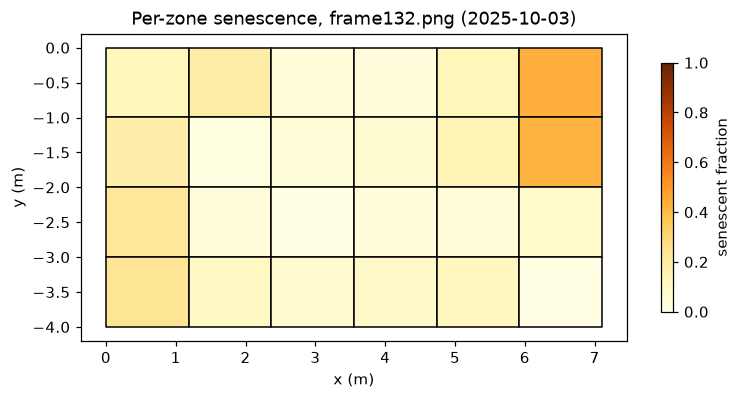

          frame        date  zone  plant_cover  senescent_frac  \
0  frame132.png  2025-10-03     1     0.871885        0.125473   
1  frame132.png  2025-10-03     2     0.807590        0.190227   
2  frame132.png  2025-10-03     3     0.842958        0.042916   
3  frame132.png  2025-10-03     4     0.889278        0.032579   
4  frame132.png  2025-10-03     5     0.807590        0.136421   

                                            geometry  
0  POLYGON ((1.184 -0.999, 1.184 0, 0 0, 0 -0.999...  
1  POLYGON ((2.368 -0.999, 2.368 0, 1.184 0, 1.18...  
2  POLYGON ((3.552 -0.999, 3.552 0, 2.368 0, 2.36...  
3  POLYGON ((4.736 -0.999, 4.736 0, 3.552 0, 3.55...  
4  POLYGON ((5.92 -0.999, 5.92 0, 4.736 0, 4.736 ...  


In [15]:
z = res["zones"]
f0 = z.frame.iloc[0]
ax = z[z.frame == f0].plot(column="senescent_frac", cmap="YlOrBr", vmin=0, vmax=1, legend=True, edgecolor="k", figsize=(8, 4.2),
                           legend_kwds={"label": "senescent fraction", "shrink": 0.7})
ax.set(title=f"Per-zone senescence, {f0} ({z.date.iloc[0]})", xlabel="x (m)", ylabel="y (m)"); plt.show()
print(gpd.read_file(OUT / "capstone" / "health_zones.gpkg").head())

## Summary and exercises

**Key points**

- Phenotyping is one table: canopy cover, greenness, yellowing, counts and height, with one
  row per flight date.
- A logistic fit supplies onset, mid-point and plateau. Curvature of that curve dates the
  stages.
- CWSI needs canopy temperature, air temperature and a non-stressed baseline. The thermal
  frame in Section 6 is built because the LUMS folder has no thermal imagery.
- The capstone function writes the table, the curves, a GeoPackage and a short report from a
  folder of frames.

**GeoLattice functions used:** `rs.uav.frame_traits`, `rs.uav.trait_table`, `rs.uav.summarize_dates`,
`rs.uav.fit_logistic`, `rs.uav.detect_stages`, `rs.uav.growth_rates`, `rs.uav.cwsi`,
`rs.uav.health_summary`.

**Exercises**

1. Rerun `phenotype_pipeline` with `exg_threshold=None` (Otsu). How do the canopy-cover fit and
   its stage dates change?
2. Add a VARI-based cover column to `traits` and fit a logistic to it. Does VARI date the
   canopy closure differently from ExG?
3. In Section 6, raise `vpd` to 3.5 kPa without changing the canopy temperatures. What happens
   to the empirical CWSI, and why?
4. Extend the pipeline to write a plot-level GeoPackage in a real CRS, given an orthomosaic
   GeoTIFF and plot polygons (`rs.uav.plants_per_area`, `rs.uav.health_summary` with
   rasterised zones).

**References**

- Chaudhry, H., Rana, S. and Jaleel, A. (2026). UAV-based crop reconstruction and trait
  estimation using RGB imagery without external geospatial infrastructure. *Computers and
  Electronics in Agriculture* (accepted).
- Idso, S. B. et al. (1981). Normalizing the stress-degree-day parameter for environmental
  variability. *Agricultural Meteorology*, 24, 45-55.
- Idso, S. B. (1982). Non-water-stressed baselines: a key to measuring and interpreting plant
  water stress. *Agricultural Meteorology*, 27, 59-70.
- Zhang, X. et al. (2003). Monitoring vegetation phenology using MODIS. *Remote Sensing of
  Environment*, 84, 471-475 (logistic phenology and curvature-based stage dates).
- Jones, H. G. (1999). Use of infrared thermometry for estimation of stomatal conductance as a
  possible aid to irrigation scheduling. *Agricultural and Forest Meteorology*, 95, 139-149.
